In [ ]:
1) A imagem original da Lena gray possui resolução 512 x 512 pixels. Decime essa imagem para
256 x 256, 128 x 128 e 64 x 64. Exiba as imagens lado a lado e do mesmo tamanho que a imagem
original. Comente.

In [ ]:
# Questão 1 — Comentários

A imagem original possui 512 × 512 pixels. A decimação será feita
por subamostragem: selecionaremos um pixel a cada 2, 4 e 8 posições
nas linhas e nas colunas.

As imagens resultantes terão 256 × 256, 128 × 128 e 64 × 64 pixels.
Todas serão exibidas lado a lado, com a mesma área visual.

Não utilizaremos redimensionamento por interpolação: a subamostragem
seleciona pixels existentes, sem calcular novos valores.

In [2]:
%pip install --upgrade "matplotlib==3.9.4" pillow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
%matplotlib inline

from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image

print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)

NumPy: 2.2.6
Matplotlib: 3.9.4


/home/jean_raposo/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [55]:
image_path = Path("dataset/lena2.tif")

if not image_path.is_file():
    raise FileNotFoundError(
        f"Imagem não encontrada: {image_path}. "
        "Verifique o caminho e a pasta de execução do notebook."
    )

with Image.open(image_path) as imagem:
    # "L" representa escala de cinza de 8 bits.
    lena_original = np.array(imagem.convert("L"))

altura, largura = lena_original.shape
print(f"Original: {altura} x {largura}")

if lena_original.shape != (512, 512):
    raise ValueError(
        f"A imagem deve ter 512 x 512 pixels, mas possui "
        f"{altura} x {largura}. Selecione o arquivo correto."
    )

Original: 512 x 512


In [13]:
# Seleciona uma amostra a cada N linhas e N colunas.
# copy() mantém cada matriz independente da original.
lena_256 = lena_original[::2, ::2].copy()
lena_128 = lena_original[::4, ::4].copy()
lena_64 = lena_original[::8, ::8].copy()

versoes = [
    (lena_original, 1, 512),
    (lena_256, 2, 256),
    (lena_128, 4, 128),
    (lena_64, 8, 64),
]

for imagem, fator, tamanho in versoes[1:]:
    if imagem.shape != (tamanho, tamanho):
        raise ValueError(f"Dimensão incorreta para o fator {fator}.")

    print(
        f"Decimada {fator}x: "
        f"{imagem.shape[0]} x {imagem.shape[1]}"
    )

Decimada 2x: 256 x 256
Decimada 4x: 128 x 128
Decimada 8x: 64 x 64


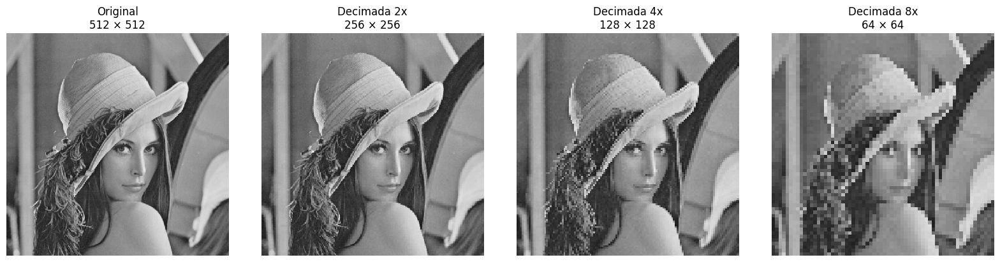

In [14]:
fig, axes = plt.subplots(
    1, 4,
    figsize=(16, 4),
    layout="constrained",
)

for ax, (imagem, fator, tamanho) in zip(axes, versoes):
    ax.imshow(
        imagem,
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest",
        resample=False,
        aspect="equal",
    )

    titulo = "Original" if fator == 1 else f"Decimada {fator}x"
    ax.set_title(f"{titulo}\n{tamanho} × {tamanho}")
    ax.set_axis_off()

plt.show()

In [ ]:
## Comentário dos resultados

A decimação reduz a resolução espacial da imagem. Apesar de diminuir a qualidade, a versão 256 × 256
ainda preserva boa parte da estrutura, enquanto a versão 128 × 128
apresenta perda perceptível de detalhes. Em 64 × 64, a perda de
informação espacial é significativa.

Como todas as imagens são exibidas no mesmo tamanho visual, os pixels
das versões menores ocupam uma área maior, tornando a pixelação mais
evidente. A ampliação para visualização não recupera os detalhes perdidos.

A subamostragem sem filtragem prévia pode provocar aliasing, produzindo
padrões artificiais e serrilhamento em regiões com detalhes finos.
Para reduzir esse efeito, normalmente aplica-se um filtro passa-baixas
adequado ao fator de decimação antes da subamostragem.

In [ ]:
2) Exiba os canais da Lena color. Explique por que cada canal é exibido em níveis de cinza embora
representem as componente R, G e B.

In [ ]:
# Questão 2 — Comentários

Uma imagem RGB possui três canais: vermelho (R), verde (G) e azul (B).
Cada canal contém a intensidade de uma dessas componentes em cada pixel.

Vamos separar os três canais e exibi-los individualmente em escala de
cinza, ao lado da imagem colorida original.

In [56]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

image_path = Path("dataset/lena3.tif")

if not image_path.is_file():
    raise FileNotFoundError(
        f"Imagem não encontrada: {image_path}. Ajuste o caminho."
    )

with Image.open(image_path) as imagem:
    lena_color = np.array(imagem.convert("RGB"))

print(f"Dimensões da imagem RGB: {lena_color.shape}")

# A última dimensão armazena os canais na ordem R, G e B.
canal_r = lena_color[:, :, 0].copy()
canal_g = lena_color[:, :, 1].copy()
canal_b = lena_color[:, :, 2].copy()

print(f"Canal R: {canal_r.shape}")
print(f"Canal G: {canal_g.shape}")
print(f"Canal B: {canal_b.shape}")

Dimensões da imagem RGB: (512, 512, 3)
Canal R: (512, 512)
Canal G: (512, 512)
Canal B: (512, 512)


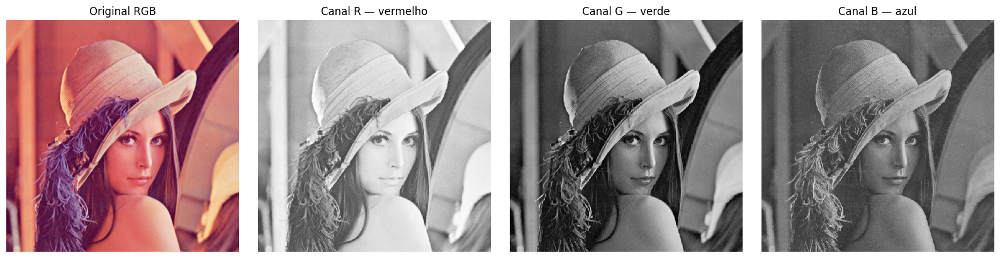

In [8]:
fig, axes = plt.subplots(
    1, 4,
    figsize=(16, 4),
    layout="constrained",
)

# A imagem original mantém suas cores.
axes[0].imshow(lena_color)
axes[0].set_title("Original RGB")

# Os canais são exibidos como matrizes de intensidade.
for ax, canal, titulo in zip(
    axes[1:],
    [canal_r, canal_g, canal_b],
    ["Canal R — vermelho", "Canal G — verde", "Canal B — azul"],
):
    ax.imshow(
        canal,
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest",
    )
    ax.set_title(titulo)

for ax in axes:
    ax.set_axis_off()

plt.show()

In [ ]:
## Comentário dos resultados

Os canais R, G e B representam, respectivamente, a intensidade das
componentes vermelha, verde e azul em cada pixel. Individualmente,
cada canal é uma matriz de valores de intensidade, sem as outras duas
componentes necessárias para formar a imagem RGB completa.

Nesta visualização, os valores são representados em escala de cinza:
valores próximos de 0 aparecem escuros, e valores próximos de 255
aparecem claros. Portanto, uma região clara no canal R indica uma
intensidade elevada da componente vermelha, e não que essa região
seja branca na imagem original. O mesmo raciocínio vale para G e B.

Os canais aparecem em cinza porque escolhemos essa forma de representar
suas intensidades usando cmap="gray". Também seria possível exibi-los
com tonalidades de suas respectivas cores, mas a escala de cinza
facilita a comparação da distribuição de intensidade entre os canais.

In [ ]:
3) Quantos bits por pixel temos na Lena color e quantos na Lena gray? Quantize a Lena gray com 6,
4, 2 e 1 bit por pixel. Exiba a imagem original e versões quantizadas lado a lado e comente os
resultados

In [ ]:
# Questão 3 — Comentários

A Lena color, em RGB com 8 bits por canal, possui 24 bits por pixel:
8 bits para vermelho, 8 para verde e 8 para azul.

A Lena gray de 8 bits possui 8 bits por pixel e pode representar
256 níveis de cinza.

Vamos reduzir a quantidade de níveis para:

- 6 bits: 64 níveis;
- 4 bits: 16 níveis;
- 2 bits: 4 níveis;
- 1 bit: 2 níveis.

A quantização modifica os níveis de intensidade, mantendo a resolução
espacial de 512 × 512 pixels.

In [57]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = Path("dataset")
gray_path = dataset_path / "lena2.tif"
color_path = dataset_path / "lena3.tif"

for caminho in [gray_path, color_path]:
    if not caminho.is_file():
        raise FileNotFoundError(
            f"Imagem não encontrada: {caminho}. "
            "Execute o notebook a partir da pasta Lista 01 "
            "e confira o nome do arquivo."
        )

# Verifica os formatos originais antes de qualquer conversão.
with Image.open(gray_path) as imagem:
    if imagem.mode != "L":
        raise ValueError(
            f"Esperada Lena gray de 8 bits (modo L); encontrado {imagem.mode}."
        )
    lena_original = np.array(imagem)

with Image.open(color_path) as imagem:
    if imagem.mode != "RGB":
        raise ValueError(
            f"Esperada Lena color RGB; encontrado {imagem.mode}."
        )
    lena_color = np.array(imagem)

if lena_original.shape != (512, 512):
    raise ValueError(
        f"Esperada imagem cinza 512 x 512; encontrado {lena_original.shape}."
    )

bits_por_canal = lena_color.dtype.itemsize * 8
bits_color = lena_color.shape[2] * bits_por_canal
bits_gray = lena_original.dtype.itemsize * 8

print(f"Lena color: {bits_color} bits por pixel")
print(f"Lena gray: {bits_gray} bits por pixel")
print(f"Resolução da Lena gray: {lena_original.shape}")

Lena color: 24 bits por pixel
Lena gray: 8 bits por pixel
Resolução da Lena gray: (512, 512)


In [18]:
def quantizar(imagem, bits):
    """Quantiza uma imagem uint8 e retorna intensidades para exibição."""
    if imagem.dtype != np.uint8:
        raise TypeError("A imagem deve possuir valores uint8.")

    if not 1 <= bits <= 8:
        raise ValueError("O número de bits deve estar entre 1 e 8.")

    niveis = 2 ** bits
    passo = 256 // niveis

    # Cada intervalo de intensidade recebe um índice.
    # Exemplo para 1 bit: 0–127 -> 0; 128–255 -> 1.
    indices = imagem.astype(np.uint16) // passo

    # Mapeia os índices para a faixa completa de exibição.
    quantizada = np.rint(
        indices.astype(np.float64) * 255 / (niveis - 1)
    ).astype(np.uint8)

    return quantizada


lena_6bits = quantizar(lena_original, 6)
lena_4bits = quantizar(lena_original, 4)
lena_2bits = quantizar(lena_original, 2)
lena_1bit = quantizar(lena_original, 1)

versoes_quantizadas = [
    (lena_6bits, 6),
    (lena_4bits, 4),
    (lena_2bits, 2),
    (lena_1bit, 1),
]

for imagem, bits in versoes_quantizadas:
    niveis_usados = np.unique(imagem).size
    niveis_possiveis = 2 ** bits

    assert imagem.shape == lena_original.shape
    assert niveis_usados <= niveis_possiveis

    print(
        f"{bits} bit(s): até {niveis_possiveis} níveis; "
        f"{niveis_usados} utilizados; dimensão {imagem.shape}"
    )

6 bit(s): até 64 níveis; 56 utilizados; dimensão (512, 512)
4 bit(s): até 16 níveis; 15 utilizados; dimensão (512, 512)
2 bit(s): até 4 níveis; 4 utilizados; dimensão (512, 512)
1 bit(s): até 2 níveis; 2 utilizados; dimensão (512, 512)


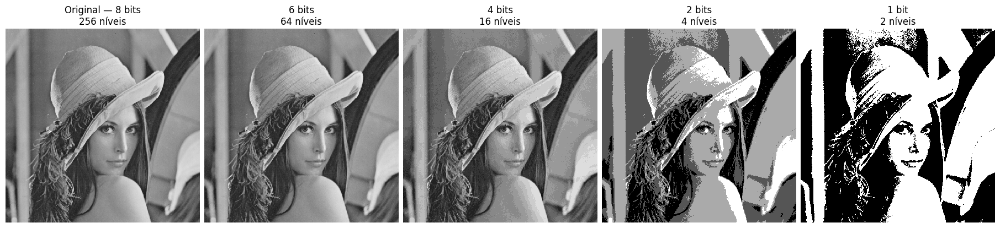

In [19]:
imagens = [
    lena_original,
    lena_6bits,
    lena_4bits,
    lena_2bits,
    lena_1bit,
]

titulos = [
    "Original — 8 bits\n256 níveis",
    "6 bits\n64 níveis",
    "4 bits\n16 níveis",
    "2 bits\n4 níveis",
    "1 bit\n2 níveis",
]

fig, axes = plt.subplots(
    1, 5,
    figsize=(18, 4),
    layout="constrained",
)

for ax, imagem, titulo in zip(axes, imagens, titulos):
    ax.imshow(
        imagem,
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest",
    )
    ax.set_title(titulo)
    ax.set_axis_off()

plt.show()

In [ ]:
## Comentário dos resultados

A Lena color possui 24 bits por pixel, considerando três canais RGB
com 8 bits cada, enquanto a Lena gray possui 8 bits por pixel.
A quantização reduz a quantidade de níveis de cinza, sem modificar
a resolução espacial da imagem.

Com 6 bits, as diferenças em relação à original tendem a ser discretas.
Com 4 bits, as transições entre intensidades ficam mais perceptíveis,
principalmente em regiões de variação suave. Com 2 bits, ocorre forte
posterização, com apenas quatro níveis disponíveis. Com 1 bit, a imagem
possui apenas preto e branco, perdendo grande parte das gradações de
brilho e dos detalhes que dependem delas.

Diferentemente da decimação da questão 1, a quantização não reduz a
quantidade de pixels: ela reduz a resolução de intensidade.

In [ ]:
4) Crie uma imagem sintética cinza (resolução 256 x 256 pixels) com nível 128. Crie um quadrado
(32x32 pixels) no centro e aumente o nível de cinza desse quadrado até que ele esteja no limite da
percepção. Repita o processo, mas dessa vez diminuindo o nível de cinza do quadrado central. Você
nota alguma ilusão de óptica? Comente os resultados e explique por que a percepção humana do
brilho é uniforme no logaritmo da luminância.

In [ ]:
# Questão 4 — Comentários

Será criada uma imagem sintética de 256 × 256 pixels, com nível de
cinza 128. Um quadrado de 32 × 32 pixels será colocado no centro.

Investigaremos duas situações:

- quadrado mais claro que o fundo;
- quadrado mais escuro que o fundo.

A diferença de intensidade será reduzida gradualmente até encontrar
o menor contraste que ainda permita perceber o quadrado.

In [20]:
import numpy as np
import matplotlib.pyplot as plt

tamanho_imagem = 256
tamanho_quadrado = 32
nivel_fundo = 128

# Imagem original uniforme, com intensidades de 8 bits.
imagem_original = np.full(
    (tamanho_imagem, tamanho_imagem),
    nivel_fundo,
    dtype=np.uint8,
)

# Quadrado central: índices de 112 até 143 em ambos os eixos.
inicio = (tamanho_imagem - tamanho_quadrado) // 2
fim = inicio + tamanho_quadrado


def criar_imagem_com_quadrado(nivel_quadrado):
    """Cria uma cópia com um quadrado central no nível informado."""
    if not isinstance(nivel_quadrado, (int, np.integer)):
        raise TypeError("O nível de cinza deve ser inteiro.")

    if not 0 <= nivel_quadrado <= 255:
        raise ValueError("O nível de cinza deve estar entre 0 e 255.")

    imagem = imagem_original.copy()
    imagem[inicio:fim, inicio:fim] = nivel_quadrado
    return imagem


print(f"Imagem original: {imagem_original.shape}")
print(f"Nível do fundo: {nivel_fundo}")
print(f"Quadrado central: {fim - inicio} x {fim - inicio}")

Imagem original: (256, 256)
Nível do fundo: 128
Quadrado central: 32 x 32


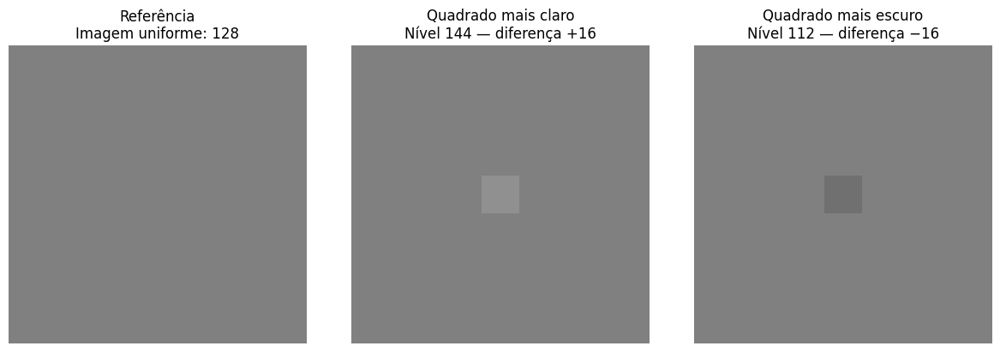

Fundo: 128
Quadrado claro: 144
Quadrado escuro: 112


In [21]:
# Diferença de intensidade em relação ao fundo.
# Ajuste cada valor separadamente para investigar sua percepção.
delta_claro = 16
delta_escuro = 16

if not isinstance(delta_claro, (int, np.integer)):
    raise TypeError("delta_claro deve ser inteiro.")

if not isinstance(delta_escuro, (int, np.integer)):
    raise TypeError("delta_escuro deve ser inteiro.")

if not 0 <= delta_claro <= 127:
    raise ValueError("delta_claro deve estar entre 0 e 127.")

if not 0 <= delta_escuro <= 128:
    raise ValueError("delta_escuro deve estar entre 0 e 128.")

nivel_claro = nivel_fundo + delta_claro
nivel_escuro = nivel_fundo - delta_escuro

imagem_clara = criar_imagem_com_quadrado(nivel_claro)
imagem_escura = criar_imagem_com_quadrado(nivel_escuro)

# Confirma o tamanho e os valores do quadrado.
assert imagem_clara[inicio:fim, inicio:fim].shape == (32, 32)
assert np.all(imagem_clara[inicio:fim, inicio:fim] == nivel_claro)
assert np.all(imagem_escura[inicio:fim, inicio:fim] == nivel_escuro)
assert np.all(imagem_original == nivel_fundo)

imagens = [imagem_original, imagem_clara, imagem_escura]
titulos = [
    "Referência\nImagem uniforme: 128",
    f"Quadrado mais claro\nNível {nivel_claro} — diferença +{delta_claro}",
    f"Quadrado mais escuro\nNível {nivel_escuro} — diferença −{delta_escuro}",
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(12, 4),
    layout="constrained",
)

for ax, imagem, titulo in zip(axes, imagens, titulos):
    ax.imshow(
        imagem,
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest",
    )
    ax.set_title(titulo)
    ax.set_axis_off()

plt.show()

print(f"Fundo: {nivel_fundo}")
print(f"Quadrado claro: {nivel_claro}")
print(f"Quadrado escuro: {nivel_escuro}")

In [ ]:
## Comentário dos resultados

A percepção do quadrado depende da diferença de intensidade em relação
ao fundo. Ao aproximar seu nível de cinza de 128, o contraste diminui
até que o quadrado deixa de ser distinguido. Os limites observados
podem variar com a iluminação, o brilho da tela e o observador.

O brilho percebido também depende do contexto. Um quadrado pode parecer
mais claro ou mais escuro em função da região ao redor, efeito associado
ao contraste simultâneo. Neste experimento, o fundo permanece constante;
por isso, algum efeito desse tipo deve ser descrito apenas se observado.

A relação entre luminância física e brilho percebido não é linear.
A lei de Weber indica, aproximadamente, que a menor diferença perceptível
é proporcional à intensidade de referência. A lei de Weber–Fechner
relaciona essa ideia a uma resposta perceptiva aproximadamente logarítmica:
aumentos proporcionais de luminância tendem a produzir incrementos
semelhantes de sensação de brilho.

In [ ]:
5) Considere a imagem Frog. Aplique um ajuste de brilho a partir do escalonamento da intensidade.
Use um ajuste na escala de 1.2. Exiba as imagens lado a lado e comente os resultados.

In [ ]:
# Questão 5 — Comentários

O brilho da imagem Frog será ajustado multiplicando cada intensidade
por 1,2:

I_saida = 1,2 × I_original

Os resultados acima de 255 serão limitados a 255, pois utilizaremos
uma imagem de 8 bits por canal. A imagem original será preservada.

In [22]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

image_path = Path("dataset/frog.tif")
fator_brilho = 1.2

if not image_path.is_file():
    raise FileNotFoundError(
        f"Imagem não encontrada: {image_path}. Confira o caminho."
    )

with Image.open(image_path) as imagem:
    # Preserva imagens em cinza; representa as demais em RGB.
    modo = "L" if imagem.mode == "L" else "RGB"
    frog_original = np.array(imagem.convert(modo))

# Converte antes da multiplicação para evitar overflow de uint8.
intensidades = frog_original.astype(np.float64)
intensidades_ajustadas = intensidades * fator_brilho

# Limita à faixa de 8 bits e arredonda antes da conversão.
frog_brilho = np.rint(
    np.clip(intensidades_ajustadas, 0, 255)
).astype(np.uint8)

assert frog_brilho.shape == frog_original.shape

print(f"Dimensões: {frog_original.shape}")
print(f"Fator de brilho: {fator_brilho}")
print(
    "Valores de intensidade que excederam 255 antes do recorte:",
    np.count_nonzero(intensidades_ajustadas > 255),
)

Dimensões: (498, 621)
Fator de brilho: 1.2
Valores de intensidade que excederam 255 antes do recorte: 3913


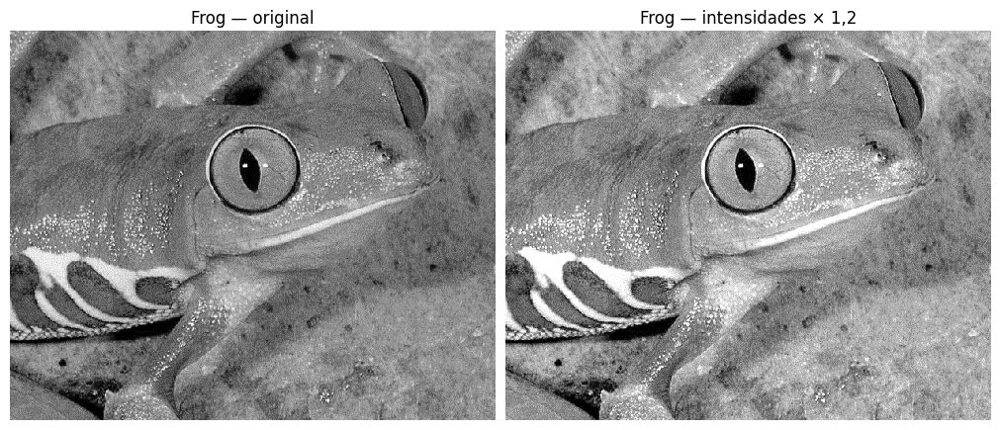

In [23]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 5),
    layout="constrained",
)

imagens = [frog_original, frog_brilho]
titulos = ["Frog — original", "Frog — intensidades × 1,2"]

for ax, imagem, titulo in zip(axes, imagens, titulos):
    if imagem.ndim == 2:
        ax.imshow(
            imagem,
            cmap="gray",
            vmin=0,
            vmax=255,
            interpolation="nearest",
        )
    else:
        ax.imshow(imagem, interpolation="nearest")

    ax.set_title(titulo)
    ax.set_axis_off()

plt.show()

In [ ]:
## Comentário dos resultados

O ajuste foi realizado multiplicando as intensidades da imagem Frog
por 1,2. Isso aumenta os valores em 20% antes do arredondamento e da
limitação à faixa de 0 a 255, tornando a imagem geralmente mais clara.
Pixels com intensidade zero permanecem inalterados.

As regiões mais claras podem sofrer saturação, pois valores acima de
255 são limitados ao máximo permitido. Esse recorte pode eliminar
diferenças entre intensidades elevadas e reduzir detalhes nessas regiões.
Nas áreas que não saturam, o escalonamento preserva a proporcionalidade
das intensidades, aproximadamente, considerando o arredondamento.

In [ ]:
6) Considere a imagem Frog. Aplique um ajuste de contraste a partir da modificação do gamma.
Use gamma = 1.5. Exiba as imagens lado a lado e comente os resultados.

In [ ]:
# Questão 6 — Comentários

Aplicaremos à imagem Frog uma transformação de potência com gamma = 1,5:

I_saida = 255 × (I_original / 255)^1,5

As intensidades são normalizadas para o intervalo de 0 a 1 antes
da transformação. Como o expoente é maior que 1, as intensidades
intermediárias diminuem, enquanto os extremos 0 e 255 permanecem fixos.

A transformação será aplicada à imagem original, sem utilizar
o resultado do ajuste de brilho da questão 5.

In [24]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

image_path = Path("dataset/frog.tif")
gamma = 1.5

if not image_path.is_file():
    raise FileNotFoundError(
        f"Imagem não encontrada: {image_path}. Confira o caminho."
    )

with Image.open(image_path) as imagem:
    # Preserva imagens em cinza; representa as demais em RGB.
    modo = "L" if imagem.mode == "L" else "RGB"
    frog_original = np.array(imagem.convert(modo))

# Normaliza as intensidades para o intervalo [0, 1].
frog_normalizada = frog_original.astype(np.float64) / 255.0

# Transformação gamma: s = r ** gamma.
frog_transformada = frog_normalizada ** gamma

# Retorna à representação de 8 bits.
frog_gamma = np.rint(
    np.clip(frog_transformada * 255.0, 0, 255)
).astype(np.uint8)

assert frog_gamma.shape == frog_original.shape

print(f"Dimensões: {frog_original.shape}")
print(f"Gamma utilizado: {gamma}")
print("Convenção: saída = 255 × (entrada / 255) ** gamma")

Dimensões: (498, 621)
Gamma utilizado: 1.5
Convenção: saída = 255 × (entrada / 255) ** gamma


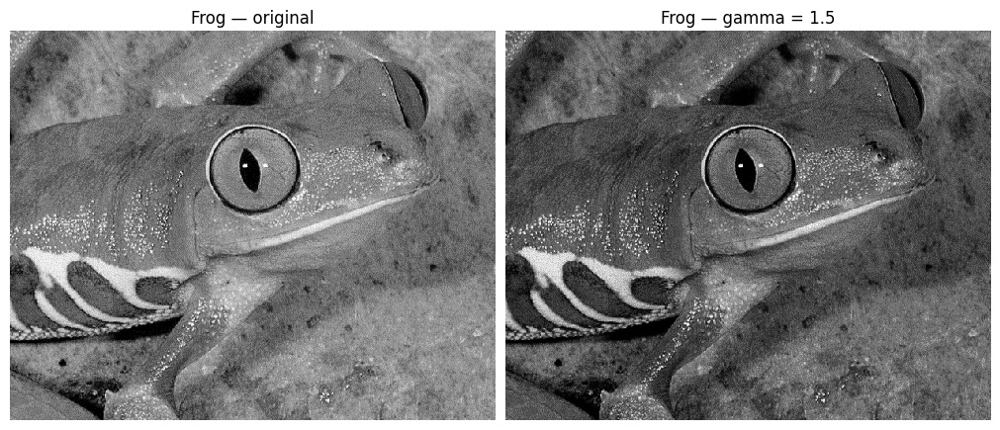

In [25]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 5),
    layout="constrained",
)

imagens = [frog_original, frog_gamma]
titulos = ["Frog — original", f"Frog — gamma = {gamma}"]

for ax, imagem, titulo in zip(axes, imagens, titulos):
    if imagem.ndim == 2:
        ax.imshow(
            imagem,
            cmap="gray",
            vmin=0,
            vmax=255,
            interpolation="nearest",
        )
    else:
        ax.imshow(imagem, interpolation="nearest")

    ax.set_title(titulo)
    ax.set_axis_off()

plt.show()

In [ ]:
## Comentário dos resultados

A transformação gamma foi aplicada às intensidades normalizadas da
imagem Frog utilizando o expoente 1,5. Como valores entre 0 e 1 diminuem
quando elevados a esse expoente, os tons intermediários ficaram mais
escuros. Os extremos preto e branco permanecem fixos.

Diferentemente do escalonamento da questão 5, a transformação gamma
é não linear: seu efeito depende da intensidade de entrada. Ela
comprime diferenças nas regiões mais escuras e expande diferenças
nas regiões mais claras, antes do arredondamento. Portanto, modifica
o contraste de maneira diferente ao longo da faixa de intensidades,
em vez de aumentá-lo uniformemente.

O escurecimento pode tornar detalhes nas sombras menos perceptíveis.

In [ ]:
7) Crie 32 imagens com ruído gaussiano a partir da imagem Brain. Aplique a técnica de supressão
de ruído a partir da média das imagens. Compare com a imagem original.

In [ ]:
# Questão 7 — Comentários

Serão criadas 32 versões da imagem Brain com ruído gaussiano aditivo,
independente entre as imagens, com média zero e desvio-padrão de
20 unidades de intensidade.

A imagem recuperada será a média das 32 versões ruidosas.

Para ruídos independentes de mesma variância, a média de N imagens
reduz a variância do ruído por N e o desvio-padrão por √N.

In [26]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

image_path = Path("dataset/brain.jpg")

numero_imagens = 32
sigma_ruido = 20.0

if not image_path.is_file():
    raise FileNotFoundError(
        f"Imagem não encontrada: {image_path}. Confira o caminho."
    )

with Image.open(image_path) as imagem:
    brain_original = np.array(imagem.convert("L"))

# Ponto flutuante permite valores negativos e acima de 255.
brain_float = brain_original.astype(np.float64)

# Semente fixa para tornar o experimento reproduzível.
rng = np.random.default_rng(seed=42)

# Um campo de ruído independente para cada uma das 32 imagens.
ruidos = rng.normal(
    loc=0.0,
    scale=sigma_ruido,
    size=(numero_imagens, *brain_original.shape),
)

imagens_ruidosas = brain_float[np.newaxis, :, :] + ruidos

print(f"Imagem original: {brain_original.shape}")
print(f"Conjunto de imagens ruidosas: {imagens_ruidosas.shape}")
print(f"Quantidade de imagens: {imagens_ruidosas.shape[0]}")
print(f"Desvio-padrão do ruído adicionado: {sigma_ruido}")

Imagem original: (754, 820)
Conjunto de imagens ruidosas: (32, 754, 820)
Quantidade de imagens: 32
Desvio-padrão do ruído adicionado: 20.0


In [27]:
# Média entre as imagens, mantendo as posições dos pixels.
brain_media = imagens_ruidosas.mean(axis=0)

assert imagens_ruidosas.shape[0] == 32
assert brain_media.shape == brain_original.shape

# Erro quadrático médio (MSE) em relação à imagem original.
mse_imagens_ruidosas = np.mean(
    (imagens_ruidosas - brain_float) ** 2,
    axis=(1, 2),
)

mse_antes = mse_imagens_ruidosas.mean()
mse_depois = np.mean((brain_media - brain_float) ** 2)

sigma_teorico_media = sigma_ruido / np.sqrt(numero_imagens)
sigma_observado_media = np.std(brain_media - brain_float)

print(f"MSE médio das imagens ruidosas: {mse_antes:.2f}")
print(f"MSE da imagem média: {mse_depois:.2f}")
print(f"Fator observado de redução do MSE: {mse_antes / mse_depois:.2f}")
print()
print(f"Desvio-padrão esperado após a média: {sigma_teorico_media:.2f}")
print(f"Desvio-padrão observado após a média: {sigma_observado_media:.2f}")

MSE médio das imagens ruidosas: 399.85
MSE da imagem média: 12.49
Fator observado de redução do MSE: 32.02

Desvio-padrão esperado após a média: 3.54
Desvio-padrão observado após a média: 3.53


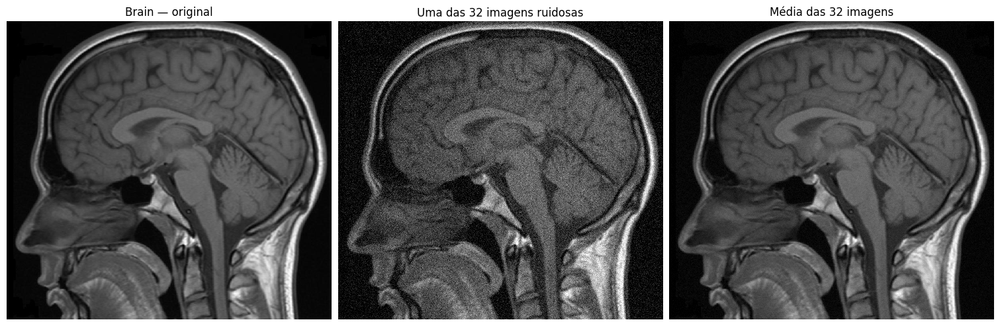

In [28]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    layout="constrained",
)

imagens = [
    brain_original,
    imagens_ruidosas[0],
    brain_media,
]

titulos = [
    "Brain — original",
    "Uma das 32 imagens ruidosas",
    "Média das 32 imagens",
]

for ax, imagem, titulo in zip(axes, imagens, titulos):
    ax.imshow(
        imagem,
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest",
    )
    ax.set_title(titulo)
    ax.set_axis_off()

plt.show()

In [ ]:
## Comentário dos resultados

Foram criadas 32 versões da imagem Brain com ruído gaussiano aditivo,
independente e de média zero. Ao calcular a média dessas imagens,
a informação original permanece, enquanto as contribuições aleatórias
do ruído tendem a se cancelar.

A imagem média apresenta menos granulação e maior semelhança com a
original do que uma imagem ruidosa individual. Teoricamente, a média
de 32 imagens reduz a variância do ruído por um fator de 32 e seu
desvio-padrão por √32, aproximadamente 5,66. Para o desvio-padrão
inicial de 20, o valor esperado após a média é aproximadamente 3,54.

O ruído não desaparece completamente porque a quantidade de imagens
é finita. A técnica pressupõe imagens alinhadas, com o mesmo conteúdo,
e ruídos independentes de média zero. Essas condições são atendidas
neste experimento, pois todas as versões foram geradas a partir da
mesma imagem original.

In [ ]:
8) Calcule e exiba os histogramas das imagens Lena gray, Moon, Bay e Brain. Relacione o formato
dos histogramas com as características das imagens.

In [ ]:
# Questão 8 — Comentários

O histograma indica quantos pixels possuem cada nível de cinza,
de 0 (preto) a 255 (branco).

Serão analisadas as imagens Lena gray, Moon, Bay e Brain.
Cada imagem será exibida ao lado de seu histograma.

In [29]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = Path("dataset")

arquivos = {
    "Lena gray": "lena2.tif",
    "Moon": "moon.jpg",
    "Bay": "bay.jpg",
    "Brain": "brain.jpg",
}

imagens = {}
histogramas = {}

for nome, arquivo in arquivos.items():
    image_path = dataset_path / arquivo

    if not image_path.is_file():
        raise FileNotFoundError(
            f"Imagem não encontrada: {image_path}. Confira o caminho."
        )

    with Image.open(image_path) as imagem:
        imagens[nome] = np.array(imagem.convert("L"))

    # Conta os pixels em cada intensidade inteira de 0 a 255.
    histogramas[nome] = np.bincount(
        imagens[nome].ravel(),
        minlength=256,
    )

    # A soma das contagens deve ser igual ao total de pixels.
    assert histogramas[nome].sum() == imagens[nome].size

    print(
        f"{nome}: dimensão {imagens[nome].shape}; "
        f"{imagens[nome].size} pixels"
    )

Lena gray: dimensão (512, 512); 262144 pixels
Moon: dimensão (1024, 750); 768000 pixels
Bay: dimensão (683, 1024); 699392 pixels
Brain: dimensão (754, 820); 618280 pixels


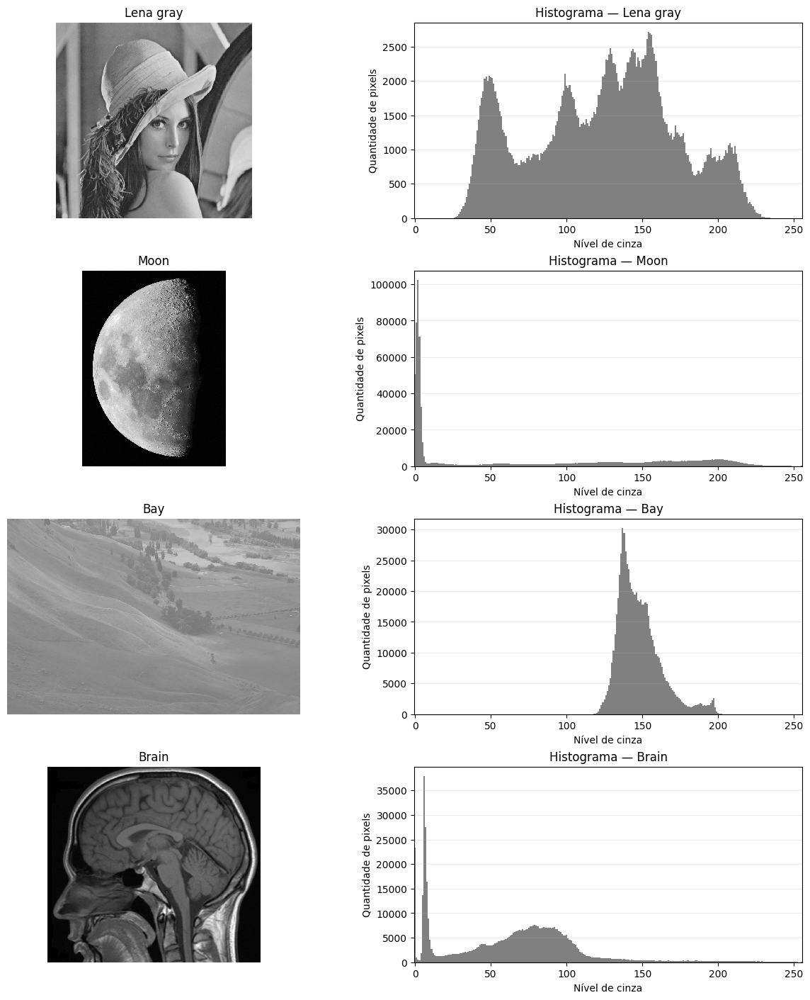

In [31]:
fig, axes = plt.subplots(
    4, 2,
    figsize=(12, 14),
    layout="constrained",
)

niveis = np.arange(256)

for linha, nome in enumerate(arquivos):
    imagem = imagens[nome]
    histograma = histogramas[nome]

    # Imagem com escala de intensidade fixa.
    axes[linha, 0].imshow(
        imagem,
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest",
    )
    axes[linha, 0].set_title(nome)
    axes[linha, 0].set_axis_off()

    # Histograma: contagem de pixels por nível.
    axes[linha, 1].bar(
        niveis,
        histograma,
        width=1.0,
        color="gray",
    )
    axes[linha, 1].set_title(f"Histograma — {nome}")
    axes[linha, 1].set_xlabel("Nível de cinza")
    axes[linha, 1].set_ylabel("Quantidade de pixels")
    axes[linha, 1].set_xlim(-0.5, 255.5)
    axes[linha, 1].grid(axis="y", alpha=0.25)

plt.show()

In [32]:
for nome, imagem in imagens.items():
    porcentagem_escuros = 100 * np.mean(imagem < 85)
    porcentagem_intermediarios = 100 * np.mean(
        (imagem >= 85) & (imagem < 170)
    )
    porcentagem_claros = 100 * np.mean(imagem >= 170)

    nivel_mais_frequente = np.argmax(histogramas[nome])

    print(f"\n{nome}")
    print(f"Intensidade mínima: {imagem.min()}")
    print(f"Intensidade máxima: {imagem.max()}")
    print(f"Intensidade média: {imagem.mean():.2f}")
    print(f"Nível mais frequente: {nivel_mais_frequente}")
    print(f"Pixels escuros (0–84): {porcentagem_escuros:.1f}%")
    print(f"Pixels intermediários (85–169): {porcentagem_intermediarios:.1f}%")
    print(f"Pixels claros (170–255): {porcentagem_claros:.1f}%")


Lena gray
Intensidade mínima: 25
Intensidade máxima: 245
Intensidade média: 124.04
Nível mais frequente: 154
Pixels escuros (0–84): 23.2%
Pixels intermediários (85–169): 59.7%
Pixels claros (170–255): 17.1%

Moon
Intensidade mínima: 0
Intensidade máxima: 255
Intensidade média: 75.38
Nível mais frequente: 2
Pixels escuros (0–84): 57.7%
Pixels intermediários (85–169): 21.5%
Pixels claros (170–255): 20.8%

Bay
Intensidade mínima: 114
Intensidade máxima: 212
Intensidade média: 148.00
Nível mais frequente: 137
Pixels escuros (0–84): 0.0%
Pixels intermediários (85–169): 92.1%
Pixels claros (170–255): 7.9%

Brain
Intensidade mínima: 0
Intensidade máxima: 255
Intensidade média: 63.86
Nível mais frequente: 6
Pixels escuros (0–84): 68.5%
Pixels intermediários (85–169): 28.6%
Pixels claros (170–255): 2.9%


In [ ]:
## Comentário dos resultados

Os histogramas mostram a distribuição dos níveis de cinza das imagens.
Na Lena gray, por ser uma imagem com diversas variações de níveis de cinza,
possui um histograma bem destribuído, e a maior concentração ocorre em 160,
relacionada às regiões claras da imagem. Na Moon, observa-se o nível de cinza
bem próximo de 0, coerente com o vazio do espaço,as crateras lunares e a
sombra na lua. Na Bay, a distribuição é majoritariamente em 160,
associada às regiões do campo da imagem. Na Brain, destaca-se um pico próximo de 0,
relacionado ao fundo da imagem.

As concentrações próximas de zero correspondem a regiões escuras,
enquanto aquelas próximas de 255 correspondem a regiões claras.
Picos indicam intensidades frequentes, e uma distribuição mais espalhada
indica maior diversidade de níveis de cinza.

In [ ]:
9) Aplique a equalização de histogramas nas imagens Lena gray, Moon, Bay e Brain. Compare o
resultado com as imagens originais.

In [ ]:
# Questão 9 — Comentários

A equalização global transforma as intensidades usando a distribuição
acumulada do histograma da imagem inteira.

O objetivo é redistribuir os níveis de cinza, aumentando o aproveitamento
da faixa de intensidades. Isso pode melhorar o contraste de imagens
cujos pixels estejam concentrados em uma faixa estreita.

Serão comparadas as imagens originais e equalizadas de Lena gray,
Moon, Bay e Brain, juntamente com seus histogramas.

In [34]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = Path("dataset")

arquivos = {
    "Lena gray": "lena2.tif",
    "Moon": "moon.jpg",
    "Bay": "bay.jpg",
    "Brain": "brain.jpg",
}

imagens_originais = {}

for nome, arquivo in arquivos.items():
    image_path = dataset_path / arquivo

    if not image_path.is_file():
        raise FileNotFoundError(
            f"Imagem não encontrada: {image_path}. Confira o caminho."
        )

    with Image.open(image_path) as imagem:
        imagens_originais[nome] = np.array(imagem.convert("L"))

    print(f"{nome}: {imagens_originais[nome].shape}")

Lena gray: (512, 512)
Moon: (1024, 750)
Bay: (683, 1024)
Brain: (754, 820)


In [35]:
def equalizar_histograma(imagem):
    """Equalização global para uma imagem 2D de tipo uint8."""
    if imagem.ndim != 2 or imagem.dtype != np.uint8:
        raise TypeError("A entrada deve ser uma imagem 2D do tipo uint8.")

    if imagem.size == 0:
        raise ValueError("A imagem não pode estar vazia.")

    # Histograma: quantidade de pixels em cada nível de cinza.
    histograma = np.bincount(imagem.ravel(), minlength=256)

    # CDF: contagem acumulada de pixels.
    acumulada = histograma.cumsum()

    niveis_presentes = np.flatnonzero(histograma)
    primeiro_nivel = niveis_presentes[0]
    cdf_min = acumulada[primeiro_nivel]

    # Evita divisão por zero no caso de uma imagem constante.
    if cdf_min == imagem.size:
        return imagem.copy()

    # Tabela que associa cada intensidade original a uma nova.
    tabela = (
        (acumulada.astype(np.float64) - cdf_min)
        / (imagem.size - cdf_min)
        * 255
    )

    tabela = np.rint(np.clip(tabela, 0, 255)).astype(np.uint8)

    # Aplica a transformação sem modificar a imagem original.
    return tabela[imagem]


imagens_equalizadas = {}
histogramas_originais = {}
histogramas_equalizados = {}

for nome, original in imagens_originais.items():
    equalizada = equalizar_histograma(original)
    imagens_equalizadas[nome] = equalizada

    histogramas_originais[nome] = np.bincount(
        original.ravel(), minlength=256
    )
    histogramas_equalizados[nome] = np.bincount(
        equalizada.ravel(), minlength=256
    )

    assert equalizada.shape == original.shape
    assert equalizada.dtype == np.uint8
    assert histogramas_equalizados[nome].sum() == original.size

    print(
        f"{nome}: faixa original [{original.min()}, {original.max()}] "
        f"→ faixa equalizada [{equalizada.min()}, {equalizada.max()}]"
    )

Lena gray: faixa original [25, 245] → faixa equalizada [0, 255]
Moon: faixa original [0, 255] → faixa equalizada [0, 255]
Bay: faixa original [114, 212] → faixa equalizada [0, 255]
Brain: faixa original [0, 255] → faixa equalizada [0, 255]


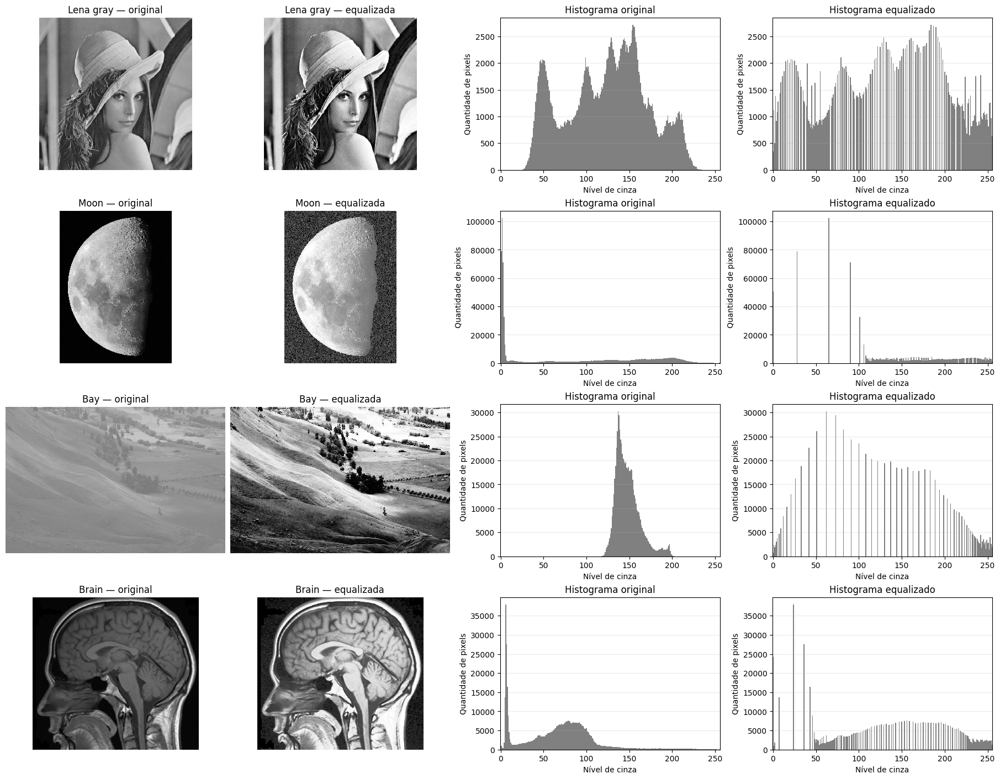

In [36]:
fig, axes = plt.subplots(
    4, 4,
    figsize=(18, 14),
    layout="constrained",
)

niveis = np.arange(256)

for linha, nome in enumerate(arquivos):
    original = imagens_originais[nome]
    equalizada = imagens_equalizadas[nome]

    # Imagens.
    for coluna, imagem, titulo in [
        (0, original, f"{nome} — original"),
        (1, equalizada, f"{nome} — equalizada"),
    ]:
        ax = axes[linha, coluna]
        ax.imshow(
            imagem,
            cmap="gray",
            vmin=0,
            vmax=255,
            interpolation="nearest",
        )
        ax.set_title(titulo)
        ax.set_axis_off()

    # Histogramas.
    for coluna, histograma, titulo in [
        (2, histogramas_originais[nome], "Histograma original"),
        (3, histogramas_equalizados[nome], "Histograma equalizado"),
    ]:
        ax = axes[linha, coluna]
        ax.bar(niveis, histograma, width=1.0, color="gray")
        ax.set_title(titulo)
        ax.set_xlabel("Nível de cinza")
        ax.set_ylabel("Quantidade de pixels")
        ax.set_xlim(-0.5, 255.5)
        ax.grid(axis="y", alpha=0.25)

    # Mesma escala vertical para os dois histogramas de cada imagem.
    limite_y = 1.05 * max(
        histogramas_originais[nome].max(),
        histogramas_equalizados[nome].max(),
    )
    axes[linha, 2].set_ylim(0, limite_y)
    axes[linha, 3].set_ylim(0, limite_y)

plt.show()

In [ ]:
## Comentário dos resultados

A equalização global redistribuiu os níveis de cinza das imagens usando
a distribuição acumulada de seus histogramas. Em regiões cujas
intensidades eram muito frequentes, a transformação pode aumentar
a separação entre níveis próximos, tornando certos detalhes mais
perceptíveis. O efeito depende da distribuição de intensidade de
cada imagem, podendo ser mais evidente quando a faixa utilizada
originalmente é estreita.

A transformação não garante um histograma perfeitamente uniforme,
pois as intensidades são discretas e todos os pixels de um mesmo
nível recebem o mesmo valor de saída. Ela também pode alterar o
brilho médio, realçar ruído ou produzir uma aparência menos natural.

A resolução espacial permanece inalterada. A equalização modifica
as intensidades, mas não recupera informações que não estavam
presentes na imagem original.

In [ ]:
10) Aplique a equalização adaptativa de histogramas nas imagens Lena gray, Moon, Bay e Brain.
Utilize blocos de tamanho 8x8 e 16x16 pixels. Compare os resultados com o que foi obtido na
Questão 9.

In [ ]:
# Questão 10 — Comentários

A equalização global utiliza uma única transformação para toda a imagem.
A equalização adaptativa calcula transformações locais, permitindo ajustar
o contraste de regiões com características diferentes.

Serão utilizados blocos de 8 × 8 e 16 × 16 pixels nas imagens Lena gray,
Moon, Bay e Brain.

A implementação interpola as transformações entre regiões vizinhas
para reduzir transições abruptas nas bordas dos blocos.

In [38]:
%pip install --upgrade scikit-image

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.8/14.8 MB 4.2 MB/s eta 0:00:00m eta 0:00:010:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 328.1/328.1 KB 3.1 MB/s eta 0:00:003.0 MB/s eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.7/37.7 MB 3.2 MB/s eta 0:00:00m eta 0:00:010:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.5/226.5 KB 3.6 MB/s eta 0:00:005.3 MB/s eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 3.6 MB/s eta 0:00:00 MB/s eta 0:00:01:01
Note: you may need to restart the kernel to use updated packages.


In [39]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage import exposure

dataset_path = Path("dataset")

arquivos = {
    "Lena gray": "lena2.tif",
    "Moon": "moon.jpg",
    "Bay": "bay.jpg",
    "Brain": "brain.jpg",
}

imagens_originais = {}

for nome, arquivo in arquivos.items():
    image_path = dataset_path / arquivo

    if not image_path.is_file():
        raise FileNotFoundError(
            f"Imagem não encontrada: {image_path}. Confira o caminho."
        )

    with Image.open(image_path) as imagem:
        imagens_originais[nome] = np.array(imagem.convert("L"))

    print(f"{nome}: {imagens_originais[nome].shape}")

Lena gray: (512, 512)
Moon: (1024, 750)
Bay: (683, 1024)
Brain: (754, 820)


In [40]:
def equalizar_global(imagem):
    """Mesma estratégia de equalização global usada na questão 9."""
    histograma = np.bincount(imagem.ravel(), minlength=256)
    acumulada = histograma.cumsum()

    primeiro_nivel = np.flatnonzero(histograma)[0]
    cdf_min = acumulada[primeiro_nivel]

    if cdf_min == imagem.size:
        return imagem.copy()

    tabela = (
        (acumulada.astype(np.float64) - cdf_min)
        / (imagem.size - cdf_min)
        * 255
    )

    tabela = np.rint(np.clip(tabela, 0, 255)).astype(np.uint8)
    return tabela[imagem]


def equalizar_adaptativa(imagem, tamanho_bloco):
    """Equalização adaptativa com blocos definidos em pixels."""
    resultado = exposure.equalize_adapthist(
        imagem,
        kernel_size=(tamanho_bloco, tamanho_bloco),
        clip_limit=1.0,
        nbins=256,
    )

    # A biblioteca retorna intensidades em ponto flutuante entre 0 e 1.
    return np.rint(
        np.clip(resultado, 0, 1) * 255
    ).astype(np.uint8)


resultados = {}

for nome, original in imagens_originais.items():
    resultados[nome] = {
        "Original": original,
        "Global": equalizar_global(original),
        "Adaptativa 8 × 8": equalizar_adaptativa(original, 8),
        "Adaptativa 16 × 16": equalizar_adaptativa(original, 16),
    }

    for metodo, imagem in resultados[nome].items():
        assert imagem.shape == original.shape
        assert imagem.dtype == np.uint8

    print(f"{nome}: equalizações concluídas.")

Lena gray: equalizações concluídas.
Moon: equalizações concluídas.
Bay: equalizações concluídas.
Brain: equalizações concluídas.


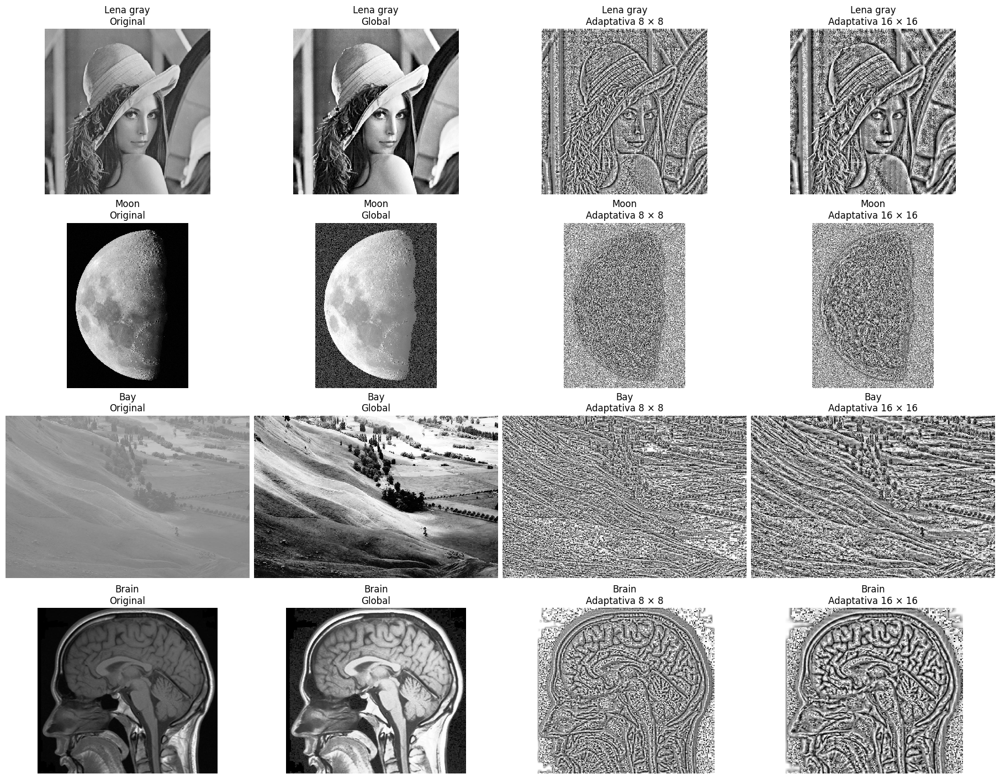

In [41]:
fig, axes = plt.subplots(
    4, 4,
    figsize=(18, 14),
    layout="constrained",
)

for linha, (nome, versoes) in enumerate(resultados.items()):
    for coluna, (metodo, imagem) in enumerate(versoes.items()):
        ax = axes[linha, coluna]

        ax.imshow(
            imagem,
            cmap="gray",
            vmin=0,
            vmax=255,
            interpolation="nearest",
        )
        ax.set_title(f"{nome}\n{metodo}")
        ax.set_axis_off()

plt.show()

In [ ]:
## Comentário dos resultados

A equalização global utiliza o histograma da imagem inteira, enquanto
a equalização adaptativa considera distribuições locais de intensidade.
Por isso, o método adaptativo pode revelar detalhes em regiões que
receberam pouco contraste com a transformação global.

Os blocos de 8 × 8 pixels trabalham em uma escala mais local e podem
realçar pequenas variações de intensidade, incluindo ruído. Os blocos
de 16 × 16 consideram regiões maiores e tendem a produzir um ajuste
menos sensível às pequenas variações locais. Entretanto, a aparência
final depende das características de cada imagem.

Como não foi utilizada limitação de contraste, regiões quase uniformes
podem apresentar amplificação intensa de ruído e uma aparência artificial.
A interpolação entre regiões reduz transições abruptas nas bordas dos
blocos, mas não elimina esses efeitos.

A equalização adaptativa não é necessariamente superior em todos os
casos: a escolha do tamanho dos blocos depende do equilíbrio entre
visibilidade dos detalhes, amplificação do ruído e aparência desejada.

In [ ]:
11) Exiba a imagem Balloons lado a lado com os seus canais R, G e B. Os canais devem ser
exibidos como imagens monocromáticas. Explique.

In [ ]:
# Questão 11 — Comentários

A imagem colorida será separada nos canais vermelho (R), verde (G)
e azul (B). Cada canal será exibido como uma imagem em escala de cinza,
indicando a intensidade daquela componente em cada pixel.

In [43]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

image_path = Path("dataset/balloons.tif")

if not image_path.is_file():
    raise FileNotFoundError(
        f"Imagem não encontrada: {image_path}. Confira o caminho."
    )

with Image.open(image_path) as imagem:
    balloons_original = np.array(imagem.convert("RGB"))

# A última dimensão contém as componentes na ordem R, G e B.
balloons_r = balloons_original[:, :, 0].copy()
balloons_g = balloons_original[:, :, 1].copy()
balloons_b = balloons_original[:, :, 2].copy()

print(f"Imagem RGB: {balloons_original.shape}")
print(f"Canal R: {balloons_r.shape}")
print(f"Canal G: {balloons_g.shape}")
print(f"Canal B: {balloons_b.shape}")

for canal in [balloons_r, balloons_g, balloons_b]:
    assert canal.shape == balloons_original.shape[:2]

Imagem RGB: (163, 355, 3)
Canal R: (163, 355)
Canal G: (163, 355)
Canal B: (163, 355)


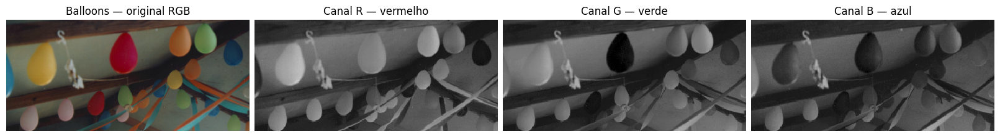

In [44]:
fig, axes = plt.subplots(
    1, 4,
    figsize=(16, 4),
    layout="constrained",
)

# A original é exibida em cores.
axes[0].imshow(balloons_original)
axes[0].set_title("Balloons — original RGB")

# Cada componente é representada em escala de cinza.
for ax, canal, titulo in zip(
    axes[1:],
    [balloons_r, balloons_g, balloons_b],
    ["Canal R — vermelho", "Canal G — verde", "Canal B — azul"],
):
    ax.imshow(
        canal,
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest",
    )
    ax.set_title(titulo)

for ax in axes:
    ax.set_axis_off()

plt.show()

In [ ]:
## Comentário dos resultados

Cada canal representa a intensidade de uma componente da imagem RGB.
Na exibição em escala de cinza, regiões claras indicam valores elevados
da componente correspondente, enquanto regiões escuras indicam valores
baixos.

Assim, um balão com forte componente vermelha tende a aparecer claro
no canal R, mas sua aparência nos canais G e B depende das intensidades
dessas outras componentes. Regiões próximas do branco apresentam valores
elevados nos três canais, enquanto regiões próximas do preto apresentam
valores baixos nos três.

Os canais aparecem em cinza porque suas intensidades foram representadas
com cmap="gray". Isso não significa que deixaram de representar vermelho,
verde ou azul: apenas escolhemos uma escala monocromática para visualizar
os valores de cada componente. A imagem colorida resulta da combinação
dos três canais.

In [ ]:
12) Converta a imagem Balloons para níveis de cinza a partir da média dos canais. Em seguida
converta utilizando a função de conversão padrão. Exiba as imagens lado a lado e explique por que
elas são diferentes.

In [ ]:
# Questão 12 — Comentários

Serão comparados dois métodos:

1. Média aritmética: cinza = (R + G + B) / 3.
2. Conversão padrão do Pillow: cinza ≈ 0,299R + 0,587G + 0,114B.

A média atribui o mesmo peso aos três canais. A conversão padrão utiliza
pesos diferentes para representar aproximadamente a sensibilidade
visual humana às componentes de cor.

In [45]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

image_path = Path("dataset/balloons.tif")

if not image_path.is_file():
    raise FileNotFoundError(
        f"Imagem não encontrada: {image_path}. Confira o caminho."
    )

with Image.open(image_path) as imagem:
    imagem_rgb = imagem.convert("RGB")

    balloons_original = np.array(imagem_rgb)

    # Conversão padrão da biblioteca Pillow.
    balloons_cinza_padrao = np.array(imagem_rgb.convert("L"))

# Converte para ponto flutuante antes de calcular a média.
# axis=2 corresponde à dimensão dos canais R, G e B.
media_canais = balloons_original.astype(np.float64).mean(axis=2)

balloons_cinza_media = np.rint(media_canais).astype(np.uint8)

assert balloons_cinza_media.shape == balloons_original.shape[:2]
assert balloons_cinza_padrao.shape == balloons_original.shape[:2]

print(f"Original RGB: {balloons_original.shape}")
print(f"Cinza pela média: {balloons_cinza_media.shape}")
print(f"Cinza pela conversão padrão: {balloons_cinza_padrao.shape}")

Original RGB: (163, 355, 3)
Cinza pela média: (163, 355)
Cinza pela conversão padrão: (163, 355)


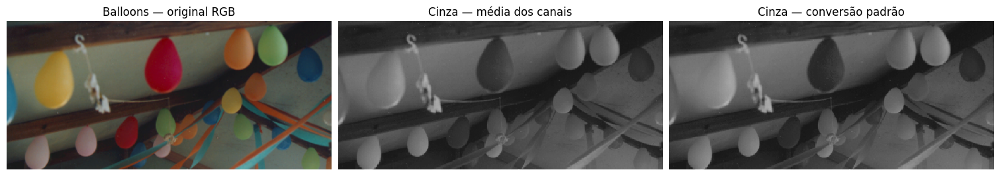

In [46]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    layout="constrained",
)

axes[0].imshow(balloons_original)
axes[0].set_title("Balloons — original RGB")

for ax, imagem, titulo in [
    (axes[1], balloons_cinza_media, "Cinza — média dos canais"),
    (axes[2], balloons_cinza_padrao, "Cinza — conversão padrão"),
]:
    ax.imshow(
        imagem,
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest",
    )
    ax.set_title(titulo)

for ax in axes:
    ax.set_axis_off()

plt.show()

In [ ]:
## Comentário dos resultados

A média aritmética atribui a mesma importância às componentes R, G e B.
Já a conversão padrão do Pillow utiliza uma soma ponderada, com maior
peso para o verde, seguido pelo vermelho e pelo azul. Essa ponderação
representa aproximadamente a diferença de sensibilidade visual humana
às componentes de cor.

Por isso, regiões com predominância de verde tendem a ficar mais claras
na conversão padrão do que na média simples, enquanto regiões com
predominância de azul tendem a ficar mais escuras. Para componentes
vermelhas isoladas, a ponderação também produz uma intensidade um pouco
menor que a média. Quando R, G e B têm valores iguais, os dois métodos
produzem essencialmente o mesmo resultado.

As diferenças observadas decorrem dos pesos utilizados na combinação
dos canais.

In [ ]:
13) Converta a imagem Peppers_color para níveis de cinza. Aplique uma binarização por limiar
global para destacar apenas a cor vermelha. Em seguida, use a imagem binária como máscara e
aplique na imagem original. Explique por que a segmentação contém algumas imperfeições
indesejadas.

In [ ]:
# Questão 13 — Comentários

A imagem Peppers color será convertida para escala de cinza.
Em seguida, aplicaremos um único limiar à imagem inteira para tentar
selecionar as regiões vermelhas.

A máscara resultante será aplicada à imagem RGB original:
os pixels selecionados manterão suas cores, e os demais ficarão pretos.

Como diferentes cores podem apresentar intensidades semelhantes em
escala de cinza, a segmentação não será perfeita.

In [47]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

image_path = Path("dataset/peppers3.tif")

if not image_path.is_file():
    raise FileNotFoundError(
        f"Imagem não encontrada: {image_path}. Confira o caminho."
    )

with Image.open(image_path) as imagem:
    imagem_rgb = imagem.convert("RGB")
    peppers_original = np.array(imagem_rgb)
    peppers_cinza = np.array(imagem_rgb.convert("L"))

print(f"Original RGB: {peppers_original.shape}")
print(f"Imagem em cinza: {peppers_cinza.shape}")

Original RGB: (512, 512, 3)
Imagem em cinza: (512, 512)


In [48]:
limiar = 120

if not 0 <= limiar <= 255:
    raise ValueError("O limiar deve estar entre 0 e 255.")

# Limiar global: a mesma regra é aplicada a todos os pixels.
# True indica um pixel selecionado.
mascara = peppers_cinza < limiar

# Representação binária para exibição: preto ou branco.
mascara_binaria = mascara.astype(np.uint8) * 255

# Mantém as cores originais apenas nos pixels selecionados.
peppers_segmentada = np.zeros_like(peppers_original)
peppers_segmentada[mascara] = peppers_original[mascara]

assert mascara.shape == peppers_cinza.shape
assert peppers_segmentada.shape == peppers_original.shape
assert np.array_equal(
    peppers_segmentada[mascara],
    peppers_original[mascara],
)

print(f"Limiar utilizado: {limiar}")
print(f"Regra: selecionar intensidades menores que {limiar}")
print(f"Pixels selecionados: {100 * mascara.mean():.1f}%")

Limiar utilizado: 120
Regra: selecionar intensidades menores que 120
Pixels selecionados: 50.9%


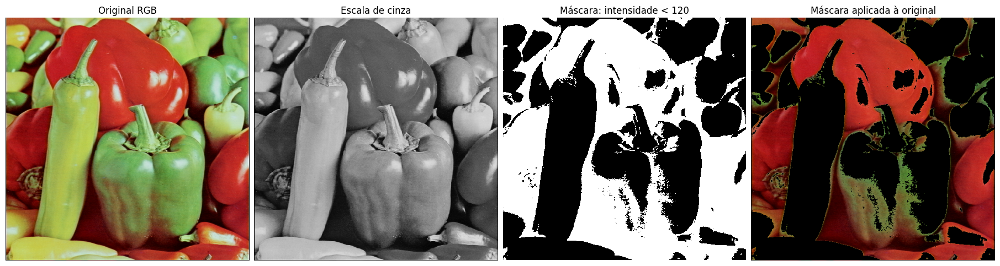

In [49]:
fig, axes = plt.subplots(
    1, 4,
    figsize=(18, 5),
    layout="constrained",
)

axes[0].imshow(peppers_original)
axes[0].set_title("Original RGB")

axes[1].imshow(
    peppers_cinza,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest",
)
axes[1].set_title("Escala de cinza")

axes[2].imshow(
    mascara_binaria,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest",
)
axes[2].set_title(f"Máscara: intensidade < {limiar}")

axes[3].imshow(peppers_segmentada)
axes[3].set_title("Máscara aplicada à original")

for ax in axes:
    ax.set_axis_off()

plt.show()

In [ ]:
## Comentário dos resultados

A imagem foi convertida para escala de cinza e segmentada utilizando
um limiar global. A máscara selecionou os pixels com intensidade abaixo
do limiar, preservando suas cores na imagem original e deixando os
demais pixels pretos.

A segmentação apresenta imperfeições porque a intensidade em cinza
não identifica exclusivamente a cor vermelha. Regiões de outras cores,
principalmente áreas escuras e sombras, podem ter intensidades semelhantes
às regiões vermelhas e também ser selecionadas. Por outro lado, reflexos
e partes mais iluminadas dos pimentões vermelhos podem ultrapassar
o limiar e ser descartados.

In [ ]:
14) Converta a imagem Guia para níveis de cinza e em seguida aplique o Otsu global. Em seguida,
aplique a binarização localmente adaptativa. Use a variância como medida de uniformidade. Qual é
o tamanho de janela que acarreta em melhor resultado?

In [ ]:
# Questão 14 — Comentários

O método de Otsu calcula um único limiar para a imagem inteira.
Isso pode dificultar a separação entre letras e papel quando
a iluminação varia ao longo da página.

Na binarização adaptativa, calcularemos um limiar para cada pixel
usando a média e a variância de sua vizinhança.

Serão comparadas janelas de 15 × 15, 31 × 31, 51 × 51 e 75 × 75 pixels.
As letras serão representadas em preto e o fundo em branco.

In [50]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import uniform_filter
from skimage.filters import threshold_otsu

image_path = Path("dataset/guia.jpg")

if not image_path.is_file():
    raise FileNotFoundError(
        f"Imagem não encontrada: {image_path}. Confira o caminho."
    )

with Image.open(image_path) as imagem:
    guia_cinza = np.array(imagem.convert("L"))

# Um único limiar calculado a partir do histograma global.
limiar_otsu = threshold_otsu(guia_cinza)

# Intensidades acima do limiar ficam brancas; as demais, pretas.
guia_otsu = (guia_cinza > limiar_otsu).astype(np.uint8) * 255

print(f"Dimensões: {guia_cinza.shape}")
print(f"Limiar de Otsu: {limiar_otsu}")

Dimensões: (3072, 1678)
Limiar de Otsu: 119


In [51]:
def binarizar_sauvola(imagem, janela, k=0.2, R=128.0):
    """Calcula um limiar local usando média e variância."""
    if janela < 3 or janela % 2 == 0:
        raise ValueError("A janela deve ser ímpar e maior ou igual a 3.")

    # Evita overflow ao elevar as intensidades ao quadrado.
    imagem_float = imagem.astype(np.float64)

    # Estatísticas locais em uma janela centrada em cada pixel.
    media_local = uniform_filter(
        imagem_float,
        size=janela,
        mode="reflect",
    )

    media_quadrados = uniform_filter(
        imagem_float ** 2,
        size=janela,
        mode="reflect",
    )

    # Pequenos valores negativos podem ocorrer por arredondamento numérico.
    variancia_local = np.maximum(
        media_quadrados - media_local ** 2,
        0.0,
    )

    desvio_local = np.sqrt(variancia_local)

    limiar_local = media_local * (
        1 + k * (desvio_local / R - 1)
    )

    binaria = (imagem_float > limiar_local).astype(np.uint8) * 255
    return binaria


janelas = [15, 31, 51, 75]
resultados_adaptativos = {}

for janela in janelas:
    binaria = binarizar_sauvola(guia_cinza, janela)
    resultados_adaptativos[janela] = binaria

    assert binaria.shape == guia_cinza.shape
    assert np.all(np.isin(binaria, [0, 255]))

    print(f"Janela {janela} × {janela}: processamento concluído.")

Janela 15 × 15: processamento concluído.
Janela 31 × 31: processamento concluído.
Janela 51 × 51: processamento concluído.
Janela 75 × 75: processamento concluído.


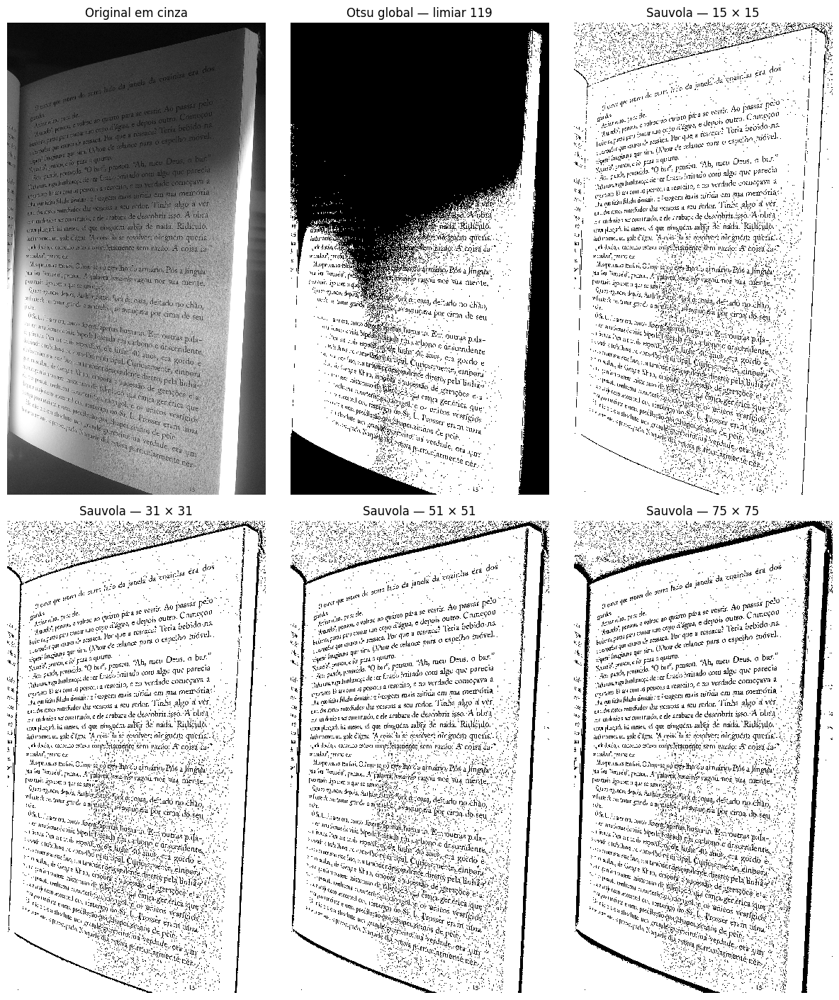

In [52]:
comparacoes = {
    "Original em cinza": guia_cinza,
    f"Otsu global — limiar {limiar_otsu}": guia_otsu,
}

for janela, imagem in resultados_adaptativos.items():
    comparacoes[f"Sauvola — {janela} × {janela}"] = imagem

fig, axes = plt.subplots(
    2, 3,
    figsize=(12, 14),
    layout="constrained",
)

for ax, (titulo, imagem) in zip(axes.ravel(), comparacoes.items()):
    ax.imshow(
        imagem,
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest",
    )
    ax.set_title(titulo)
    ax.set_axis_off()

plt.show()

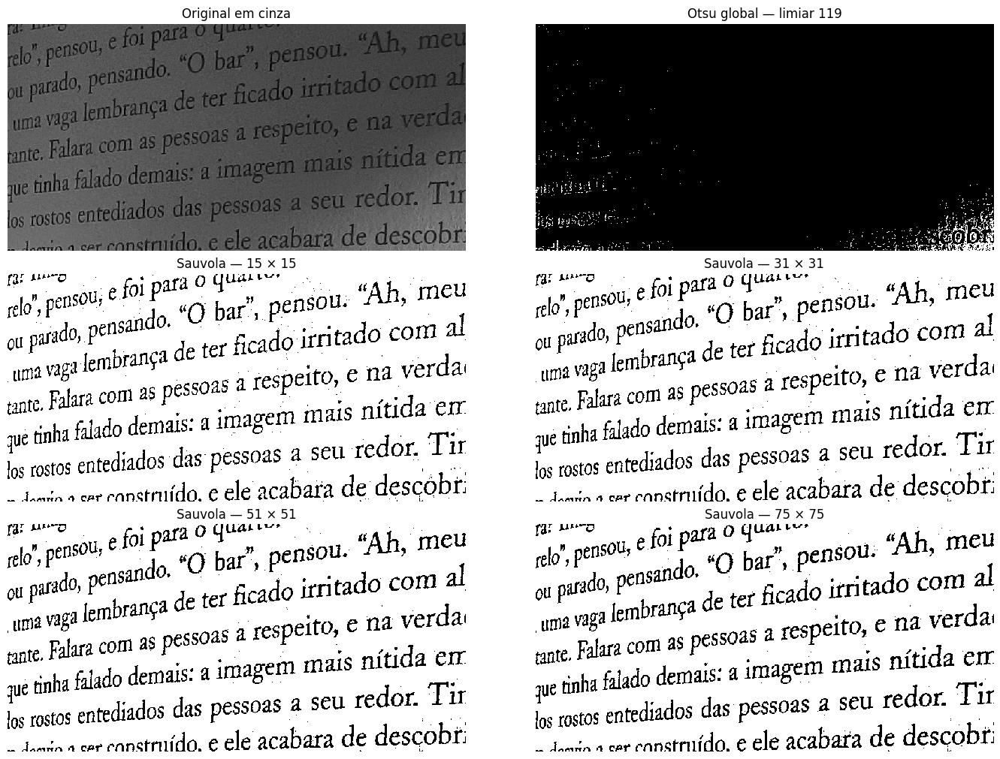

In [53]:
altura, largura = guia_cinza.shape

# Trecho da região textual da página.
linhas = slice(int(0.29 * altura), int(0.42 * altura))
colunas = slice(int(0.12 * largura), int(0.60 * largura))

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 10),
    layout="constrained",
)

for ax, (titulo, imagem) in zip(axes.ravel(), comparacoes.items()):
    ax.imshow(
        imagem[linhas, colunas],
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest",
    )
    ax.set_title(titulo)
    ax.set_axis_off()

plt.show()

In [ ]:
## Comentário dos resultados

A binarização por Otsu utilizou um único limiar para toda a imagem.
Como a fotografia apresenta iluminação desigual, partes escuras do
papel foram confundidas com as letras, prejudicando a leitura.

A binarização adaptativa de Sauvola utilizou a média e a variância local,
permitindo ajustar o limiar às condições de cada região. A variância
foi empregada como medida de uniformidade: regiões com pouca variação
apresentam variância baixa, enquanto letras, bordas e textura podem
aumentá-la.

Foram comparadas janelas de 15 × 15, 31 × 31, 51 × 51 e 75 × 75 pixels.
No trecho textual analisado, a janela de 75 × 75 apresentou melhor
continuidade das letras entre as opções testadas. Janelas muito pequenas
podem considerar apenas parte de um traço, dificultando a separação
entre texto e fundo. Entretanto, janelas excessivamente grandes podem
acompanhar pior as mudanças locais de iluminação.

Assim, a escolha da janela depende da escala dos caracteres e da
variação de iluminação, devendo considerar tanto a legibilidade
quanto a presença de manchas no fundo.